# Exercício 1

1. Gere uma amostra de tamanho $K$ de uma variável com distribuição binomial negativa com parâmetros $p$ $r$ utilizando os três métodos vistos em sala: via Bernoullis, via soma de geométricas, via recursão.
2. Compare com uma amostra gerada pelo numpy usando histogramas.
3. Compare o tempo dos três métodos como visto nos labs anteriores.



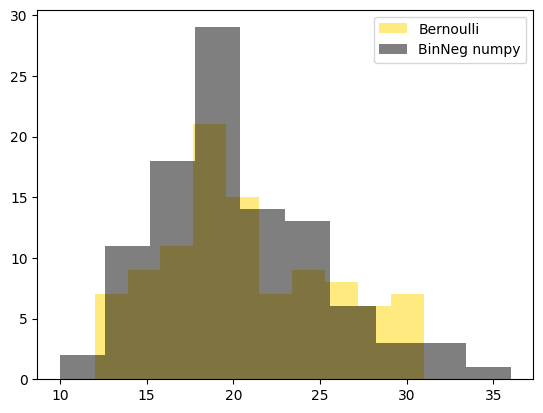

In [47]:
import numpy as np
import matplotlib.pyplot as plt
import time


r = 10
p = .5
k = 100
#Calculando a partir da bernoulli
def bin_neg_bern(r, p, k):

  amostra = []
  for i in range(k):
    n = 0
    s = 0
    while s < r:
      bern = np.random.uniform()
      n += 1
      s += bern < p
    amostra.append(n)
  return amostra



plt.hist(bin_neg_bern(r,p, k), bins=10, alpha=.5, color = 'gold', label ='Bernoulli')
plt.hist(np.random.negative_binomial(r, p, k) +r, bins=10, alpha=.5,  color='black', label ='BinNeg numpy')
plt.legend()
plt.show()

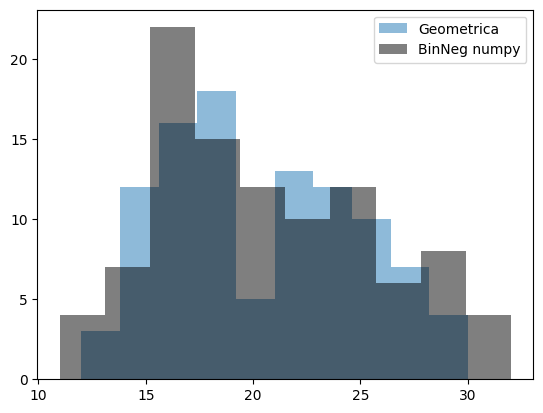

In [48]:
#Geometrica
def bin_neg_geo(r, p, k):


  amostra = []
  amostrax = []
  for j in range(k):
    amostra = []
    for i in range(r):
        u = np.random.uniform()
        num = np.log(u)
        den = np.log(1 - p)
        m = np.ceil(num/den)
        amostra.append(m)
    x = np.sum(amostra)
    amostrax.append(x)
  return amostrax
plt.hist(bin_neg_geo(r, p, k), bins =10, alpha =.5, label='Geometrica')
plt.hist(np.random.negative_binomial(r, p, k)+r, bins=10, alpha=.5,  color='black', label ='BinNeg numpy')
plt.legend()
plt.show()

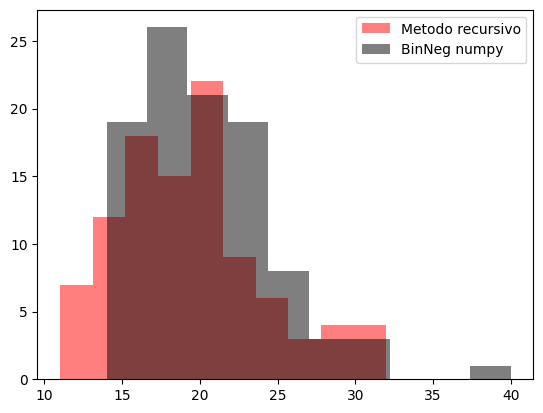

In [49]:
#Gerando via recursão
def bin_neg_rec(r, p, k):
  amostrinha = []
  for _ in range(k):
    u = np.random.uniform()
    n = r
    pi = p**r
    F = pi
    while u > F:
      pi = pi*n*(1-p)/(n-r+1)
      n += 1
      F += pi
    amostrinha.append(n)
  return amostrinha

plt.hist(bin_neg_rec(r, p, k), bins =10, color = 'red' , alpha =.5, label='Metodo recursivo')
plt.hist(np.random.negative_binomial(r, p, k)+r, bins=10, alpha=.5,  color='black', label ='BinNeg numpy')
plt.legend()
plt.show()

Comparando o tempo:

In [50]:
ps = np.linspace(0.05,0.9)
tempo_bernoullis = []
for p in ps:
    inicio = time.time()
    bin_neg_bern(r, p, k)
    tempo_bernoullis.append(time.time()- inicio)

In [51]:
tempo_geometricas = []
for p in ps:
  inicio = time.time()
  bin_neg_geo(r, p, k)
  tempo_geometricas.append(time.time()- inicio)

In [52]:
tempo_recursiva = []
for p in ps:
  inicio = time.time()
  bin_neg_rec(r, p, k)
  tempo_recursiva.append(time.time()- inicio)

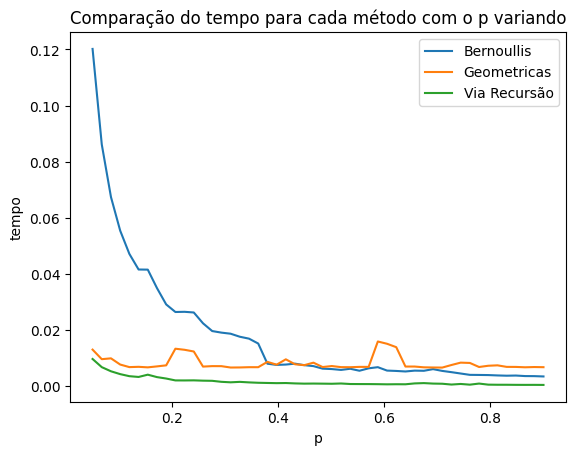

In [53]:
fig, ax = plt.subplots()
ax.plot(ps, tempo_bernoullis, label ='Bernoullis')
ax.plot(ps, tempo_geometricas, label='Geometricas')
ax.plot(ps, tempo_recursiva, label='Via Recursão')
plt.xlabel('p')
plt.legend()
plt.ylabel('tempo')
plt.title('Comparação do tempo para cada método com o p variando')
plt.show()

# Exercício 2

1.  Gere uma amostra de tamanho $K$ de uma variável aleatória com distribuição hipergeométrica com parâmetros $M,N,n$ utilizando o método de embaralhamento de Fisher–Yates.
2.  No método de Fisher-Yates, no passo (a), a gente amostra um ponto para troca entre $i$ e $N$. Pense em qual seria o problema caso a gente sempre amostrasse entre $1$ e $N$. Compare o resultado final usando essas duas versões e uma amostra gerada pelo numpy.

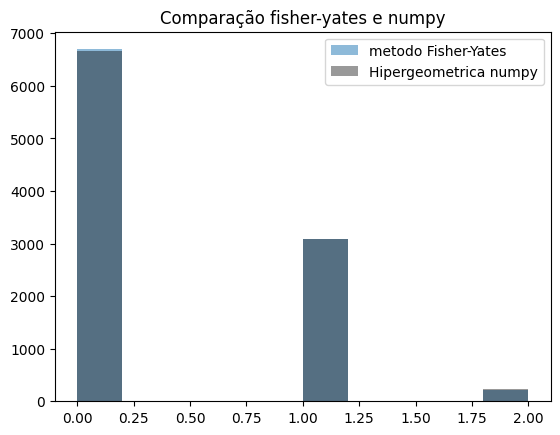

In [54]:
K = 10000

M = 2
N = 15
n = 3
def hipergeometrica(M,N,n,K):
    amostra =[]
    for _ in range(K):
        lista = [1] * M + [0] * (N)
        for i in range(n):
            u = np.random.uniform()
            j = int(np.floor(((N+M)-i)*u + i))
            lista[i],lista[j] = lista[j], lista[i]
        amostra.append(np.sum(lista[:n]))
    return amostra
hipers = hipergeometrica(M,N,n,K)
plt.hist(hipers, bins=10, alpha=.5, label='metodo Fisher-Yates')
plt.hist(np.random.hypergeometric(M, N, n, size=K), bins=10, alpha=.4, label='Hipergeometrica numpy', color='black')
plt.title('Comparação fisher-yates e numpy')
plt.legend()
plt.show()

# Exercício 3

É intuitivo esperar que, quando o tamanho total da população $M+N$ cresce muito em relação ao tamanho da amostra $n$, o fato de a amostragem ser feita sem reposição passe a ter pouca importância, pois retirar um elemento altera muito pouco a composição da população restante. Nesse caso, cada retirada deve se comportar aproximadamente como um ensaio de Bernoulli independente, com probabilidade de sucesso

$$
p=\frac{N}{M+N}.
$$

Assim, esperamos que a distribuição hipergeométrica com parâmetros $M,N,n$ se aproxime de uma distribuição binomial com parâmetros $n$ e $p$.

Compare numericamente essas duas distribuições para valores crescentes de $M$ e $N$, mantendo aproximadamente constante a proporção

$$
\frac{N}{M+N}\to p,
$$

e mantendo $n$ fixo. Verifique, por meio de simulações, se a aproximação pela distribuição binomial melhora à medida que $M+N$ aumenta.


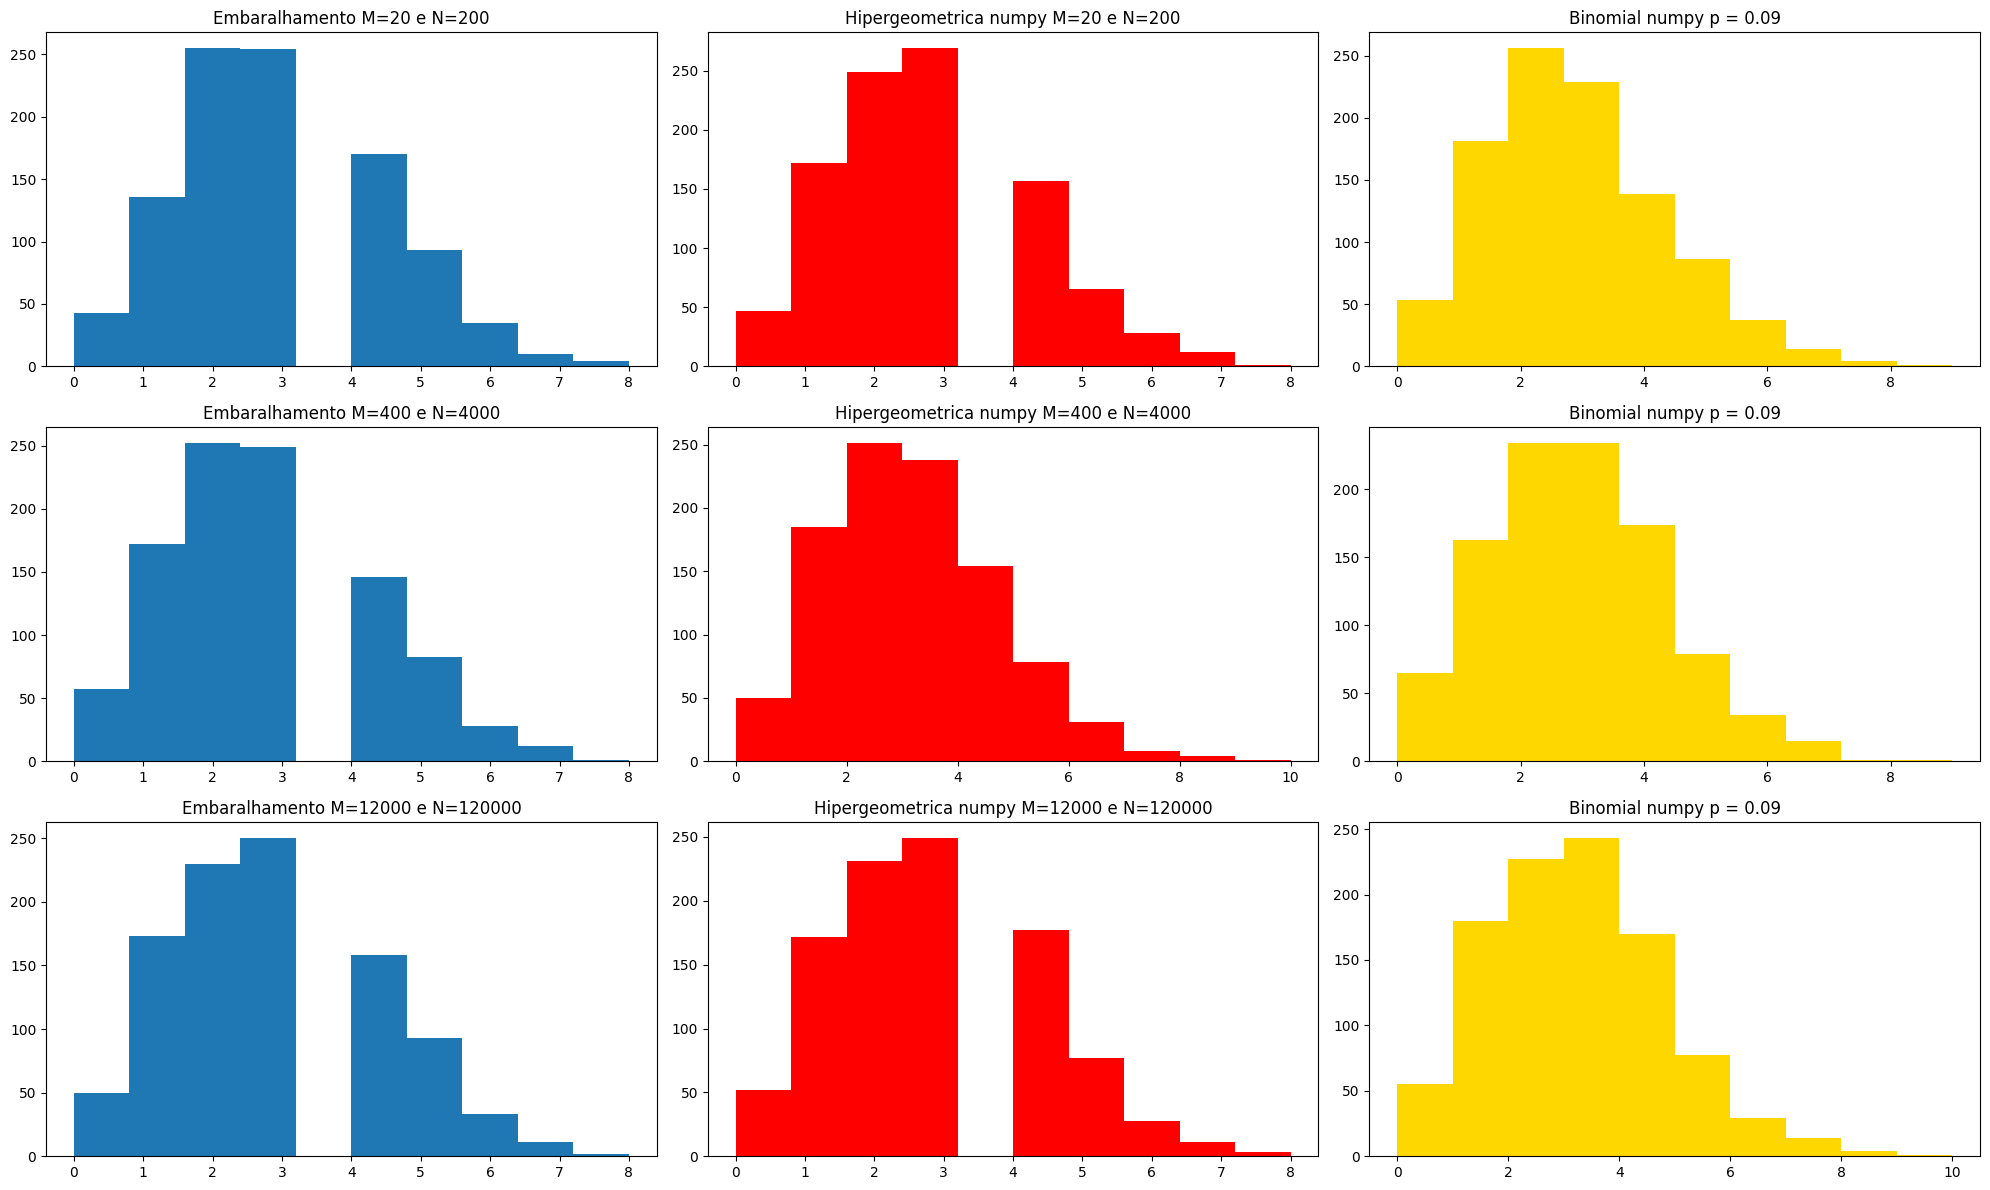

In [55]:
fig, ax = plt.subplots(3,3, figsize=(20,12))
N = 20
M = 2
n = 30
K = 1000
for i in range(3):
    M *= 10*(i+1)
    N *= 10*(i+1)
    hiper = hipergeometrica(M,N,n,K)
    ax[i][0].hist(hiper)
    ax[i][0].set_title(f'Embaralhamento M={M} e N={N}')
    ax[i][1].set_title(f'Hipergeometrica numpy M={M} e N={N}')
    ax[i][2].set_title(f'Binomial numpy p = {M/(N+M):.2f}')
    ax[i][1].hist(np.random.hypergeometric(M,N,n, size=K), color ='red')
    ax[i][2].hist(np.random.binomial(n, M/(M+N), size = K), color = 'gold')
plt.tight_layout()